### Import libraries :

In [1]:
# Step 1: Import Libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from google.cloud import bigquery
from pathlib import Path

import warnings
warnings.filterwarnings("ignore")

pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", "{:.2f}".format)

sns.set_theme(style="whitegrid")

print("Libraries imported successfully.")

Libraries imported successfully.


### Connect to BigQuery :

In [4]:
# Step 2: BigQuery Connection

PROJECT_ID = "ecommerce-sales-nabin-2026"
DATASET_ID = "devflow_raw"

client = bigquery.Client(project=PROJECT_ID)

print("BigQuery connection successful.")

BigQuery connection successful.


### Load source tables :

In [3]:
# Step 3: Load Source Tables

def load_bigquery_table(table_name):
    query = f"""
        SELECT *
        FROM `{PROJECT_ID}.{DATASET_ID}.{table_name}`
    """
    return client.query(query).to_dataframe()

users = load_bigquery_table("users")
organizations = load_bigquery_table("organizations")
product_events = load_bigquery_table("product_events")
feature_usage = load_bigquery_table("feature_usage")
api_usage = load_bigquery_table("api_usage")
subscriptions = load_bigquery_table("subscriptions")

print("All source tables loaded successfully.")

All source tables loaded successfully.


### Validate date ranges for temporal feature engineering :

In [5]:
# Step 4: Date Range Validation

date_columns = {
    "users": (users, "signup_date"),
    "product_events": (product_events, "event_timestamp"),
    "feature_usage": (feature_usage, "first_used_at"),
    "api_usage": (api_usage, "request_timestamp"),
    "subscriptions": (subscriptions, "start_date")
}

date_summary = []

for table_name, (df, column) in date_columns.items():
    date_summary.append({
        "table": table_name,
        "date_column": column,
        "minimum_date": df[column].min(),
        "maximum_date": df[column].max()
    })

date_summary = pd.DataFrame(date_summary)

display(date_summary)

,table,date_column,minimum_date,maximum_date
0,users,signup_date,2024-01-08,2026-06-23
1,product_events,event_timestamp,2024-01-15,2026-11-15
2,feature_usage,first_used_at,2024-01-17,2026-11-08
3,api_usage,request_timestamp,2024-01-10,2026-11-15
4,subscriptions,start_date,2024-01-16,2026-06-02


### Validate the proposed observation and prediction windows :

In [6]:
# Step 5: Check Available Date Coverage

print("Product event date range:")
print(product_events["event_timestamp"].min())
print(product_events["event_timestamp"].max())

print("\nAPI usage date range:")
print(api_usage["request_timestamp"].min())
print(api_usage["request_timestamp"].max())

print("\nAPI Monitoring adoption date range:")

api_monitoring = feature_usage[
    feature_usage["feature_name"] == "API Monitoring"
].copy()

print(api_monitoring["first_used_at"].min())
print(api_monitoring["first_used_at"].max())

Product event date range:
2024-01-15
2026-11-15

API usage date range:
2024-01-10
2026-11-15

API Monitoring adoption date range:
2024-01-23
2026-10-31


### Save date validation results :

In [7]:
# Step 6: Save Date Validation

OUTPUT_DIR = Path("../data/processed")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

date_summary.to_csv(
    OUTPUT_DIR / "feature_engineering_date_validation.csv",
    index=False
)

print("Date validation summary saved successfully.")

Date validation summary saved successfully.


### Create temporal window configuration :

In [8]:
# Step 7: Temporal Window Configuration

OBSERVATION_DAYS = 30
PREDICTION_DAYS = 30

DATA_END_DATE = pd.Timestamp(
    product_events["event_timestamp"].max()
)

ADOPTION_END_DATE = pd.Timestamp(
    api_monitoring["first_used_at"].max()
)

print("Observation window:", OBSERVATION_DAYS, "days")
print("Prediction window:", PREDICTION_DAYS, "days")
print("Product data end date:", DATA_END_DATE)
print("API Monitoring adoption end date:", ADOPTION_END_DATE)

Observation window: 30 days
Prediction window: 30 days
Product data end date: 2026-11-15 00:00:00
API Monitoring adoption end date: 2026-10-31 00:00:00


### Calculate the latest possible index date :

In [9]:
# Step 8: Latest Possible Index Date

SOURCE_END_DATES = {
    "product_events": pd.Timestamp(
        product_events["event_timestamp"].max()
    ),
    "api_usage": pd.Timestamp(
        api_usage["request_timestamp"].max()
    ),
    "api_monitoring": pd.Timestamp(
        api_monitoring["first_used_at"].max()
    )
}

LATEST_SOURCE_END = min(SOURCE_END_DATES.values())

LATEST_INDEX_DATE = (
    LATEST_SOURCE_END
    - pd.Timedelta(days=PREDICTION_DAYS - 1)
)

print("Source coverage cutoff:", LATEST_SOURCE_END)
print("Latest possible index date:", LATEST_INDEX_DATE)

Source coverage cutoff: 2026-10-31 00:00:00
Latest possible index date: 2026-10-02 00:00:00


### Inspect potential index dates :

In [10]:
# Step 9: Generate Candidate Index Dates

candidate_dates = pd.date_range(
    start=pd.Timestamp("2024-03-01"),
    end=LATEST_INDEX_DATE,
    freq="D"
)

candidate_date_summary = pd.DataFrame({
    "index_date": candidate_dates
})

candidate_date_summary["observation_start"] = (
    candidate_date_summary["index_date"]
    - pd.Timedelta(days=OBSERVATION_DAYS)
)

candidate_date_summary["prediction_end"] = (
    candidate_date_summary["index_date"]
    + pd.Timedelta(days=PREDICTION_DAYS - 1)
)

display(candidate_date_summary.head())
display(candidate_date_summary.tail())

,index_date,observation_start,prediction_end
0,2024-03-01,2024-01-31,2024-03-30
1,2024-03-02,2024-02-01,2024-03-31
2,2024-03-03,2024-02-02,2024-04-01
3,2024-03-04,2024-02-03,2024-04-02
4,2024-03-05,2024-02-04,2024-04-03


,index_date,observation_start,prediction_end
941,2026-09-28,2026-08-29,2026-10-27
942,2026-09-29,2026-08-30,2026-10-28
943,2026-09-30,2026-08-31,2026-10-29
944,2026-10-01,2026-09-01,2026-10-30
945,2026-10-02,2026-09-02,2026-10-31


### Check historical API Monitoring adoption before each index date :

In [11]:
# Step 10: Check Historical Adoption Eligibility

api_monitoring = api_monitoring.copy()

api_monitoring["first_used_at"] = pd.to_datetime(
    api_monitoring["first_used_at"]
)

users["signup_date"] = pd.to_datetime(
    users["signup_date"]
)

candidate_date_summary["index_date"] = pd.to_datetime(
    candidate_date_summary["index_date"]
)

# Use unique user-level first adoption dates
api_monitoring_first = (
    api_monitoring.groupby("user_id", as_index=False)
    .agg(
        api_monitoring_first_adoption=(
            "first_used_at", "min"
        )
    )
)

print("Unique API Monitoring adopters:",
      api_monitoring_first["user_id"].nunique())

display(api_monitoring_first.head())

Unique API Monitoring adopters: 2802


,user_id,api_monitoring_first_adoption
0,1,2025-07-28
1,2,2024-10-30
2,6,2025-08-26
3,7,2025-04-06
4,11,2025-03-05


### Calculate eligible users for each index date :

In [12]:
# Step 11: Calculate Eligible Users

eligibility_results = []

for index_date in candidate_date_summary["index_date"]:

    observation_start = (
        index_date - pd.Timedelta(days=OBSERVATION_DAYS)
    )

    eligible_users = users[
        users["signup_date"] <= observation_start
    ].copy()

    eligible_users = eligible_users.merge(
        api_monitoring_first,
        on="user_id",
        how="left"
    )

    eligible_users = eligible_users[
        eligible_users["api_monitoring_first_adoption"].isna()
        |
        (
            eligible_users["api_monitoring_first_adoption"]
            >= index_date
        )
    ]

    eligibility_results.append({
        "index_date": index_date,
        "observation_start": observation_start,
        "prediction_end": (
            index_date
            + pd.Timedelta(days=PREDICTION_DAYS - 1)
        ),
        "eligible_users": eligible_users["user_id"].nunique()
    })

eligibility_summary = pd.DataFrame(eligibility_results)

display(eligibility_summary.head())
display(eligibility_summary.tail())

,index_date,observation_start,prediction_end,eligible_users
0,2024-03-01,2024-01-31,2024-03-30,29
1,2024-03-02,2024-02-01,2024-03-31,30
2,2024-03-03,2024-02-02,2024-04-01,34
3,2024-03-04,2024-02-03,2024-04-02,37
4,2024-03-05,2024-02-04,2024-04-03,40


,index_date,observation_start,prediction_end,eligible_users
941,2026-09-28,2026-08-29,2026-10-27,7203
942,2026-09-29,2026-08-30,2026-10-28,7203
943,2026-09-30,2026-08-31,2026-10-29,7203
944,2026-10-01,2026-09-01,2026-10-30,7203
945,2026-10-02,2026-09-02,2026-10-31,7203


### Visualize eligible user counts :

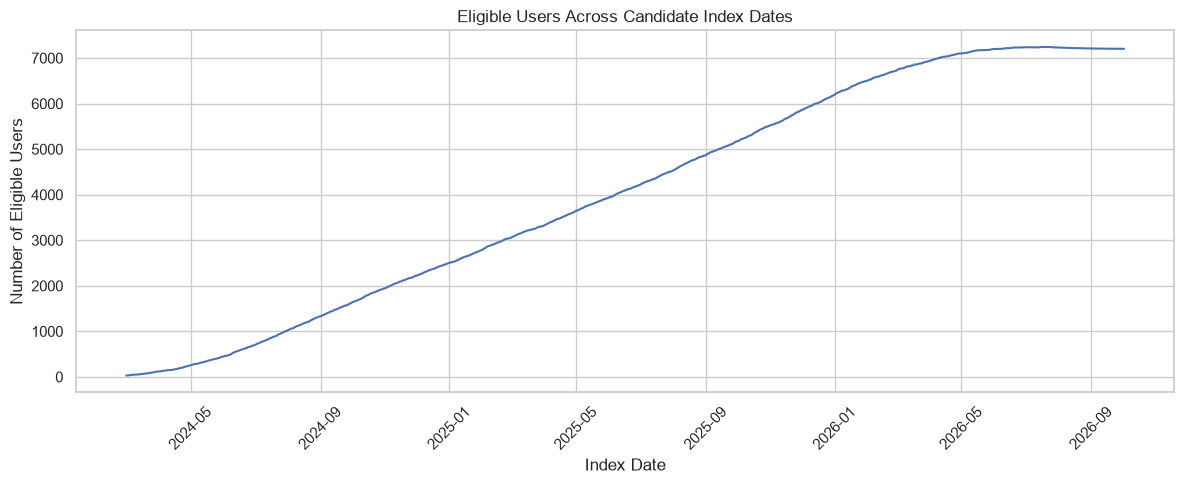

In [15]:
# Step 12: Eligible User Distribution

plt.figure(figsize=(12, 5))

sns.lineplot(
    data=eligibility_summary,
    x="index_date",
    y="eligible_users"
)

plt.title("Eligible Users Across Candidate Index Dates")
plt.xlabel("Index Date")
plt.ylabel("Number of Eligible Users")
plt.xticks(rotation=45)

plt.tight_layout()

plt.savefig(
    VISUALIZATION_DIR / "eligible_users_by_index_date.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

### Validate the final prediction cohort :

In [16]:
# Step 13: Select the final index date

FINAL_INDEX_DATE = pd.Timestamp("2026-10-02")

OBSERVATION_START = (
    FINAL_INDEX_DATE - pd.Timedelta(days=OBSERVATION_DAYS)
)

PREDICTION_END = (
    FINAL_INDEX_DATE + pd.Timedelta(days=PREDICTION_DAYS - 1)
)

print("Index date:", FINAL_INDEX_DATE.date())
print("Observation start:", OBSERVATION_START.date())
print("Prediction end:", PREDICTION_END.date())

Index date: 2026-10-02
Observation start: 2026-09-02
Prediction end: 2026-10-31


### Build the Eligible User Cohort :

In [17]:
# Step 14: Build the eligible user cohort

eligible_users_final = users[
    users["signup_date"] <= OBSERVATION_START
].copy()

eligible_users_final = eligible_users_final.merge(
    api_monitoring_first,
    on="user_id",
    how="left"
)

eligible_users_final = eligible_users_final[
    eligible_users_final["api_monitoring_first_adoption"].isna()
    |
    (
        eligible_users_final["api_monitoring_first_adoption"]
        >= FINAL_INDEX_DATE
    )
].copy()

print("Eligible users:", eligible_users_final["user_id"].nunique())

Eligible users: 7203


### Create the Feature Adoption Target Variable :

In [18]:
# Step 15: Create the target variable

eligible_users_final["feature_adopted"] = (
    eligible_users_final["api_monitoring_first_adoption"].notna()
    &
    (
        eligible_users_final["api_monitoring_first_adoption"]
        <= PREDICTION_END
    )
).astype(int)

display(
    eligible_users_final["feature_adopted"]
    .value_counts()
    .rename(index={0: "Not Adopted", 1: "Adopted"})
)

display(
    eligible_users_final["feature_adopted"]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)

feature_adopted
Not Adopted    7198
Adopted           5
Name: count, dtype: int64

feature_adopted
0   99.93
1    0.07
Name: proportion, dtype: float64

### Validate the Target Variable Distribution :

In [19]:
# Step 16: Validate target distribution

target_summary = (
    eligible_users_final
    .groupby("feature_adopted")
    .agg(
        total_users=("user_id", "nunique")
    )
    .reset_index()
)

target_summary["target_label"] = target_summary[
    "feature_adopted"
].map({
    0: "Not Adopted",
    1: "Adopted"
})

display(target_summary)

,feature_adopted,total_users,target_label
0,0,7198,Not Adopted
1,1,5,Adopted


### Analyze Monthly API Monitoring Adoption :

In [20]:
# Step 17: Analyze monthly API Monitoring adoption

api_monitoring_monthly = api_monitoring_first.copy()

api_monitoring_monthly["adoption_month"] = (
    api_monitoring_monthly["api_monitoring_first_adoption"]
    .dt.to_period("M")
)

monthly_adoption_counts = (
    api_monitoring_monthly
    .groupby("adoption_month")
    .agg(
        adopted_users=("user_id", "nunique")
    )
    .reset_index()
)

monthly_adoption_counts["adoption_month"] = (
    monthly_adoption_counts["adoption_month"].astype(str)
)

display(monthly_adoption_counts)

,adoption_month,adopted_users
0,2024-01,1
1,2024-02,1
2,2024-03,6
3,2024-04,15
4,2024-05,40
5,2024-06,49
6,2024-07,88
7,2024-08,91
8,2024-09,93
9,2024-10,121


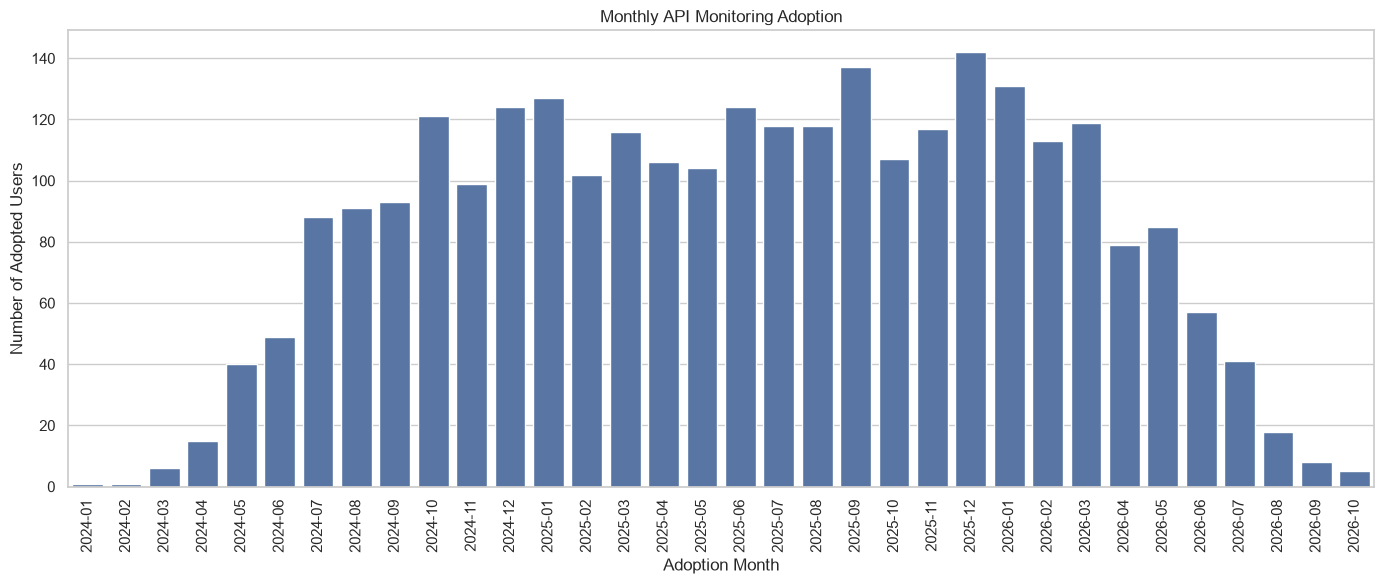

In [21]:
# Visualize monthly adoption

plt.figure(figsize=(14, 6))

sns.barplot(
    data=monthly_adoption_counts,
    x="adoption_month",
    y="adopted_users"
)

plt.title("Monthly API Monitoring Adoption")
plt.xlabel("Adoption Month")
plt.ylabel("Number of Adopted Users")
plt.xticks(rotation=90)
plt.tight_layout()

plt.savefig(
    VISUALIZATION_DIR / "monthly_api_monitoring_adoption.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

### Generate Monthly Index Dates :

In [22]:
# Step 18: Generate monthly index dates

monthly_index_dates = pd.date_range(
    start="2024-03-01",
    end="2026-10-01",
    freq="MS"
)

monthly_cohort_dates = pd.DataFrame({
    "index_date": monthly_index_dates
})

monthly_cohort_dates["observation_start"] = (
    monthly_cohort_dates["index_date"]
    - pd.Timedelta(days=OBSERVATION_DAYS)
)

monthly_cohort_dates["prediction_end"] = (
    monthly_cohort_dates["index_date"]
    + pd.Timedelta(days=PREDICTION_DAYS - 1)
)

display(monthly_cohort_dates)
print("Total monthly index dates:", len(monthly_cohort_dates))

,index_date,observation_start,prediction_end
0,2024-03-01,2024-01-31,2024-03-30
1,2024-04-01,2024-03-02,2024-04-30
2,2024-05-01,2024-04-01,2024-05-30
3,2024-06-01,2024-05-02,2024-06-30
4,2024-07-01,2024-06-01,2024-07-30
5,2024-08-01,2024-07-02,2024-08-30
6,2024-09-01,2024-08-02,2024-09-30
7,2024-10-01,2024-09-01,2024-10-30
8,2024-11-01,2024-10-02,2024-11-30
9,2024-12-01,2024-11-01,2024-12-30


Total monthly index dates: 32


### Calculate Monthly Cohort and Target Counts :

In [23]:
# Step 19: Calculate eligible users and target counts

monthly_cohort_results = []

for index_date in monthly_cohort_dates["index_date"]:

    observation_start = (
        index_date - pd.Timedelta(days=OBSERVATION_DAYS)
    )

    prediction_end = (
        index_date + pd.Timedelta(days=PREDICTION_DAYS - 1)
    )

    cohort = users[
        users["signup_date"] <= observation_start
    ].copy()

    cohort = cohort.merge(
        api_monitoring_first,
        on="user_id",
        how="left"
    )

    cohort = cohort[
        cohort["api_monitoring_first_adoption"].isna()
        |
        (
            cohort["api_monitoring_first_adoption"]
            >= index_date
        )
    ].copy()

    cohort["feature_adopted"] = (
        cohort["api_monitoring_first_adoption"].notna()
        &
        (
            cohort["api_monitoring_first_adoption"]
            <= prediction_end
        )
    ).astype(int)

    monthly_cohort_results.append({
        "index_date": index_date,
        "eligible_users": cohort["user_id"].nunique(),
        "adopted_users": int(cohort["feature_adopted"].sum()),
        "not_adopted_users": int(
            (cohort["feature_adopted"] == 0).sum()
        ),
        "adoption_rate_pct": round(
            cohort["feature_adopted"].mean() * 100, 2
        )
    })

monthly_cohort_summary = pd.DataFrame(monthly_cohort_results)

display(monthly_cohort_summary)

,index_date,eligible_users,adopted_users,not_adopted_users,adoption_rate_pct
0,2024-03-01,29,1,28,3.45
1,2024-04-01,120,5,115,4.17
2,2024-05-01,257,20,237,7.78
3,2024-06-01,446,28,418,6.28
4,2024-07-01,704,46,658,6.53
5,2024-08-01,1022,53,969,5.19
6,2024-09-01,1331,66,1265,4.96
7,2024-10-01,1638,81,1557,4.95
8,2024-11-01,1945,66,1879,3.39
9,2024-12-01,2221,85,2136,3.83


### Validate Prediction Window Coverage :

In [24]:
# Step 20: Validate prediction window coverage

api_monitoring_latest_date = (
    api_monitoring["first_used_at"].max()
)

coverage_check = monthly_cohort_dates.copy()

coverage_check["data_available"] = (
    coverage_check["prediction_end"]
    <= api_monitoring_latest_date
)

display(coverage_check)

print(
    "Latest API Monitoring adoption date:",
    api_monitoring_latest_date
)

print(
    "Fully covered prediction windows:",
    coverage_check["data_available"].sum()
)

print(
    "Incomplete prediction windows:",
    (~coverage_check["data_available"]).sum()
)

,index_date,observation_start,prediction_end,data_available
0,2024-03-01,2024-01-31,2024-03-30,True
1,2024-04-01,2024-03-02,2024-04-30,True
2,2024-05-01,2024-04-01,2024-05-30,True
3,2024-06-01,2024-05-02,2024-06-30,True
4,2024-07-01,2024-06-01,2024-07-30,True
5,2024-08-01,2024-07-02,2024-08-30,True
6,2024-09-01,2024-08-02,2024-09-30,True
7,2024-10-01,2024-09-01,2024-10-30,True
8,2024-11-01,2024-10-02,2024-11-30,True
9,2024-12-01,2024-11-01,2024-12-30,True


Latest API Monitoring adoption date: 2026-10-31 00:00:00
Fully covered prediction windows: 32
Incomplete prediction windows: 0


### Check Target Distribution Across Cohorts :

In [25]:
# Step 21: Check monthly target distribution

monthly_cohort_summary["positive_rate"] = (
    monthly_cohort_summary["adoption_rate_pct"]
)

monthly_cohort_summary["positive_class_adequate"] = (
    monthly_cohort_summary["adopted_users"] >= 20
)

display(
    monthly_cohort_summary[
        [
            "index_date",
            "eligible_users",
            "adopted_users",
            "not_adopted_users",
            "positive_rate",
            "positive_class_adequate"
        ]
    ]
)

,index_date,eligible_users,adopted_users,not_adopted_users,positive_rate,positive_class_adequate
0,2024-03-01,29,1,28,3.45,False
1,2024-04-01,120,5,115,4.17,False
2,2024-05-01,257,20,237,7.78,True
3,2024-06-01,446,28,418,6.28,True
4,2024-07-01,704,46,658,6.53,True
5,2024-08-01,1022,53,969,5.19,True
6,2024-09-01,1331,66,1265,4.96,True
7,2024-10-01,1638,81,1557,4.95,True
8,2024-11-01,1945,66,1879,3.39,True
9,2024-12-01,2221,85,2136,3.83,True


### Build the Historical User-Level Cohort Dataset :

In [26]:
# Step 22: Build the historical user-level cohort dataset

cohort_records = []

for index_date in monthly_cohort_dates["index_date"]:

    observation_start = (
        index_date - pd.Timedelta(days=OBSERVATION_DAYS)
    )

    prediction_end = (
        index_date + pd.Timedelta(days=PREDICTION_DAYS - 1)
    )

    # Select users who signed up before the observation window
    cohort = users[
        users["signup_date"] <= observation_start
    ].copy()

    # Add first API Monitoring adoption date
    cohort = cohort.merge(
        api_monitoring_first,
        on="user_id",
        how="left"
    )

    # Exclude users who adopted before the index date
    cohort = cohort[
        cohort["api_monitoring_first_adoption"].isna()
        |
        (
            cohort["api_monitoring_first_adoption"]
            >= index_date
        )
    ].copy()

    # Create future adoption target
    cohort["feature_adopted"] = (
        cohort["api_monitoring_first_adoption"].notna()
        &
        (
            cohort["api_monitoring_first_adoption"]
            <= prediction_end
        )
    ).astype(int)

    # Add cohort window information
    cohort["index_date"] = index_date
    cohort["observation_start"] = observation_start
    cohort["prediction_end"] = prediction_end

    cohort_records.append(cohort)

# Combine all monthly cohorts
ml_cohort_dataset = pd.concat(
    cohort_records,
    ignore_index=True
)

print("Total cohort records:", len(ml_cohort_dataset))
print("Unique users:", ml_cohort_dataset["user_id"].nunique())
print("Unique index dates:", ml_cohort_dataset["index_date"].nunique())

display(ml_cohort_dataset.head())

Total cohort records: 128727
Unique users: 9198
Unique index dates: 32


,user_id,organization_id,signup_date,country,user_role,acquisition_channel,is_verified,api_monitoring_first_adoption,feature_adopted,index_date,observation_start,prediction_end
0,1398,302,2024-01-10,Germany,Admin,Organic,1,2024-04-07,0,2024-03-01,2024-01-31,2024-03-30
1,9381,194,2024-01-18,Singapore,Admin,Paid Ads,1,NaT,0,2024-03-01,2024-01-31,2024-03-30
2,2037,424,2024-01-23,Singapore,Admin,Social Media,0,NaT,0,2024-03-01,2024-01-31,2024-03-30
3,9249,718,2024-01-25,Japan,Admin,Organic,0,NaT,0,2024-03-01,2024-01-31,2024-03-30
4,5559,685,2024-01-21,India,Data Analyst,Referral,1,NaT,0,2024-03-01,2024-01-31,2024-03-30


### Validate the cohort dataset :

In [27]:
# Step 23: Validate the historical cohort dataset

print("Dataset shape:", ml_cohort_dataset.shape)

print(
    "Duplicate user-index records:",
    ml_cohort_dataset.duplicated(
        subset=["user_id", "index_date"]
    ).sum()
)

print("\nTarget distribution:")

display(
    ml_cohort_dataset["feature_adopted"]
    .value_counts()
    .rename(index={
        0: "Not Adopted",
        1: "Adopted"
    })
)

print("\nTarget percentages:")

display(
    ml_cohort_dataset["feature_adopted"]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)

Dataset shape: (128727, 12)
Duplicate user-index records: 0

Target distribution:


feature_adopted
Not Adopted    126746
Adopted          1981
Name: count, dtype: int64


Target percentages:


feature_adopted
0   98.46
1    1.54
Name: proportion, dtype: float64

### Save the dataset :

In [28]:
OUTPUT_DIR = Path("../data/processed")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

In [29]:
# Save historical cohort dataset

ml_cohort_dataset.to_csv(
    OUTPUT_DIR / "historical_user_cohort_dataset.csv",
    index=False
)

print("Historical cohort dataset saved successfully.")

Historical cohort dataset saved successfully.


### Generate consecutive 30-day index dates :

In [30]:
# Step 24: Generate consecutive 30-day index dates

monthly_cohort_dates = pd.date_range(
    start="2024-03-01",
    end="2026-10-02",
    freq="30D"
)

cohort_dates = pd.DataFrame({
    "index_date": monthly_cohort_dates
})

cohort_dates["observation_start"] = (
    cohort_dates["index_date"]
    - pd.Timedelta(days=OBSERVATION_DAYS)
)

cohort_dates["prediction_end"] = (
    cohort_dates["index_date"]
    + pd.Timedelta(days=PREDICTION_DAYS - 1)
)

display(cohort_dates)

print("Total index dates:", len(cohort_dates))

,index_date,observation_start,prediction_end
0,2024-03-01,2024-01-31,2024-03-30
1,2024-03-31,2024-03-01,2024-04-29
2,2024-04-30,2024-03-31,2024-05-29
3,2024-05-30,2024-04-30,2024-06-28
4,2024-06-29,2024-05-30,2024-07-28
5,2024-07-29,2024-06-29,2024-08-27
6,2024-08-28,2024-07-29,2024-09-26
7,2024-09-27,2024-08-28,2024-10-26
8,2024-10-27,2024-09-27,2024-11-25
9,2024-11-26,2024-10-27,2024-12-25


Total index dates: 32


### Rebuild the historical cohort dataset :

In [31]:
# Step 25: Rebuild historical user-level cohorts

cohort_records = []

for index_date in cohort_dates["index_date"]:

    observation_start = (
        index_date - pd.Timedelta(days=OBSERVATION_DAYS)
    )

    prediction_end = (
        index_date + pd.Timedelta(days=PREDICTION_DAYS - 1)
    )

    cohort = users[
        users["signup_date"] <= observation_start
    ].copy()

    cohort = cohort.merge(
        api_monitoring_first,
        on="user_id",
        how="left"
    )

    cohort = cohort[
        cohort["api_monitoring_first_adoption"].isna()
        |
        (
            cohort["api_monitoring_first_adoption"]
            >= index_date
        )
    ].copy()

    cohort["feature_adopted"] = (
        cohort["api_monitoring_first_adoption"].notna()
        &
        (
            cohort["api_monitoring_first_adoption"]
            <= prediction_end
        )
    ).astype(int)

    cohort["index_date"] = index_date
    cohort["observation_start"] = observation_start
    cohort["prediction_end"] = prediction_end

    cohort_records.append(cohort)

ml_cohort_dataset = pd.concat(
    cohort_records,
    ignore_index=True
)

print("Dataset shape:", ml_cohort_dataset.shape)
print("Unique users:", ml_cohort_dataset["user_id"].nunique())

print(
    "Duplicate user-index records:",
    ml_cohort_dataset.duplicated(
        subset=["user_id", "index_date"]
    ).sum()
)

print("\nTarget distribution:")

display(
    ml_cohort_dataset["feature_adopted"]
    .value_counts()
    .rename(index={0: "Not Adopted", 1: "Adopted"})
)

print("\nTarget percentages:")

display(
    ml_cohort_dataset["feature_adopted"]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)

Dataset shape: (127219, 12)
Unique users: 9192
Duplicate user-index records: 0

Target distribution:


feature_adopted
Not Adopted    125226
Adopted          1993
Name: count, dtype: int64


Target percentages:


feature_adopted
0   98.43
1    1.57
Name: proportion, dtype: float64

### Save the corrected cohort dataset :

In [32]:
ml_cohort_dataset.to_csv(
    OUTPUT_DIR / "historical_user_cohort_dataset.csv",
    index=False
)

print("Corrected cohort dataset saved successfully.")

Corrected cohort dataset saved successfully.


### Validate source date columns :

In [33]:
# Step 27: Validate source date columns

date_validation = pd.DataFrame({
    "table": [
        "product_events",
        "api_usage",
        "feature_usage"
    ],
    "date_column": [
        "event_timestamp",
        "request_timestamp",
        "first_used_at"
    ],
    "minimum_date": [
        product_events["event_timestamp"].min(),
        api_usage["request_timestamp"].min(),
        feature_usage["first_used_at"].min()
    ],
    "maximum_date": [
        product_events["event_timestamp"].max(),
        api_usage["request_timestamp"].max(),
        feature_usage["first_used_at"].max()
    ]
})

display(date_validation)

,table,date_column,minimum_date,maximum_date
0,product_events,event_timestamp,2024-01-15,2026-11-15
1,api_usage,request_timestamp,2024-01-10,2026-11-15
2,feature_usage,first_used_at,2024-01-17,2026-11-08


#### check data types

In [34]:
# Check data types

print("Product events:")
print(product_events["event_timestamp"].dtype)

print("\nAPI usage:")
print(api_usage["request_timestamp"].dtype)

print("\nFeature usage:")
print(feature_usage["first_used_at"].dtype)

Product events:
dbdate

API usage:
dbdate

Feature usage:
dbdate


### Prepare Product Event Features :

In [35]:
# Step 28: Prepare Product Event Data

product_events = product_events.copy()

product_events["event_timestamp"] = pd.to_datetime(
    product_events["event_timestamp"]
)

print("Product Events Shape:", product_events.shape)

print("\nAvailable Columns:")
print(product_events.columns.tolist())

print("\nEvent Name Distribution:")
display(
    product_events["event_name"]
    .value_counts()
    .reset_index(name="event_count")
    .rename(columns={"index": "event_name"})
)

print("\nMissing Values:")
display(
    product_events.isnull().sum().reset_index(
        name="missing_count"
    ).rename(columns={"index": "column"})
)

Product Events Shape: (80000, 8)

Available Columns:
['event_id', 'user_id', 'event_name', 'event_timestamp', 'session_id', 'platform', 'device_type', 'event_properties']

Event Name Distribution:


,event_name,event_count
0,sdk_integrated,8163
1,login,8097
2,monitoring_enabled,8095
3,subscription_upgraded,8034
4,api_key_created,7994
5,documentation_viewed,7988
6,signup,7969
7,analytics_dashboard_viewed,7941
8,first_api_request,7866
9,webhook_created,7853



Missing Values:


,column,missing_count
0,event_id,0
1,user_id,0
2,event_name,0
3,event_timestamp,0
4,session_id,0
5,platform,0
6,device_type,0
7,event_properties,0


### Investigate Potential Target Leakage :

#### Inspect event properties

In [36]:
# Step 29A: Inspect Event Properties

print("Unique Event Properties:")
print(product_events["event_properties"].nunique())

display(
    product_events["event_properties"]
    .value_counts()
    .reset_index(name="event_count")
    .rename(columns={"index": "event_properties"})
)

print("\nSample Product Events:")
display(
    product_events[
        ["user_id", "event_name", "event_timestamp", "event_properties"]
    ].head(15)
)

Unique Event Properties:
5


,event_properties,event_count
0,success,16194
1,feature_interaction,16007
2,integration_action,16001
3,failure,15899
4,page_view,15899



Sample Product Events:


,user_id,event_name,event_timestamp,event_properties
0,7861,analytics_dashboard_viewed,2024-01-31,failure
1,2507,analytics_dashboard_viewed,2024-02-20,feature_interaction
2,8748,analytics_dashboard_viewed,2024-02-21,success
3,6657,analytics_dashboard_viewed,2024-02-25,integration_action
4,1312,analytics_dashboard_viewed,2024-02-27,page_view
5,9249,analytics_dashboard_viewed,2024-03-01,feature_interaction
6,1362,analytics_dashboard_viewed,2024-03-02,integration_action
7,1301,analytics_dashboard_viewed,2024-03-03,integration_action
8,8215,analytics_dashboard_viewed,2024-03-03,integration_action
9,6354,analytics_dashboard_viewed,2024-03-08,failure


#### Compare monitoring events with API Monitoring adoption

In [38]:
# Step 29B: Compare Monitoring Events with Feature Adoption

monitoring_events = product_events[
    product_events["event_name"] == "monitoring_enabled"
].copy()

api_monitoring_adoption = feature_usage[
    feature_usage["feature_name"] == "API Monitoring"
].copy()

# Convert both date columns to pandas datetime
monitoring_events["event_timestamp"] = pd.to_datetime(
    monitoring_events["event_timestamp"]
)

api_monitoring_adoption["first_used_at"] = pd.to_datetime(
    api_monitoring_adoption["first_used_at"]
)

api_monitoring_adoption = api_monitoring_adoption[
    ["user_id", "first_used_at"]
].rename(
    columns={
        "first_used_at": "api_monitoring_first_adoption"
    }
)

# Merge datasets
monitoring_comparison = monitoring_events.merge(
    api_monitoring_adoption,
    on="user_id",
    how="left"
)

# Calculate date difference
monitoring_comparison["date_difference"] = (
    monitoring_comparison["event_timestamp"]
    - monitoring_comparison["api_monitoring_first_adoption"]
).dt.days

# Display results
print("Monitoring Event Records:", len(monitoring_events))

print(
    "Users with API Monitoring Adoption:",
    monitoring_comparison["api_monitoring_first_adoption"].notna().sum()
)

print(
    "Events on the same date as adoption:",
    (monitoring_comparison["date_difference"] == 0).sum()
)

display(monitoring_comparison.head(15))

Monitoring Event Records: 8095
Users with API Monitoring Adoption: 2302
Events on the same date as adoption: 12


,event_id,user_id,event_name,event_timestamp,session_id,platform,device_type,event_properties,api_monitoring_first_adoption,date_difference
0,68169,1291,monitoring_enabled,2024-01-26,SESSION_68169,IDE,Desktop,feature_interaction,2024-03-27,-61.00
1,16983,4508,monitoring_enabled,2024-01-31,SESSION_16983,API,Mobile,integration_action,NaT,NaN
2,72203,4508,monitoring_enabled,2024-02-04,SESSION_72203,IDE,Desktop,failure,NaT,NaN
3,40107,2720,monitoring_enabled,2024-02-15,SESSION_40107,Web,Mobile,integration_action,NaT,NaN
4,1091,5084,monitoring_enabled,2024-02-20,SESSION_1091,IDE,Mobile,failure,NaT,NaN
5,70770,47,monitoring_enabled,2024-02-24,SESSION_70770,Web,Mobile,page_view,NaT,NaN
6,32087,5058,monitoring_enabled,2024-02-25,SESSION_32087,Web,Desktop,failure,NaT,NaN
7,60970,9570,monitoring_enabled,2024-02-26,SESSION_60970,Web,Desktop,integration_action,2024-06-18,-113.00
8,18654,2807,monitoring_enabled,2024-02-28,SESSION_18654,Web,Desktop,feature_interaction,2024-05-14,-76.00
9,20123,7861,monitoring_enabled,2024-02-28,SESSION_20123,API,Desktop,feature_interaction,NaT,NaN


### Analyze Monitoring Event Timing :

In [39]:
# Step 30: Analyze Monitoring Event Timing

matched_events = monitoring_comparison[
    monitoring_comparison["api_monitoring_first_adoption"].notna()
].copy()

matched_events["event_timing"] = np.select(
    [
        matched_events["date_difference"] < 0,
        matched_events["date_difference"] == 0,
        matched_events["date_difference"] > 0
    ],
    [
        "Before Adoption",
        "Same Date as Adoption",
        "After Adoption"
    ],
    default="Unknown"
)

# Event record distribution
timing_summary = (
    matched_events["event_timing"]
    .value_counts()
    .reset_index()
)

timing_summary.columns = ["event_timing", "event_count"]

timing_summary["percentage"] = (
    timing_summary["event_count"]
    / timing_summary["event_count"].sum()
    * 100
).round(2)

display(timing_summary)

# Unique users in each timing category
user_timing_summary = (
    matched_events.groupby("event_timing")["user_id"]
    .nunique()
    .reset_index(name="unique_users")
)

display(user_timing_summary)

,event_timing,event_count,percentage
0,After Adoption,1332,57.86
1,Before Adoption,958,41.62
2,Same Date as Adoption,12,0.52


,event_timing,unique_users
0,After Adoption,1030
1,Before Adoption,760
2,Same Date as Adoption,12


In [40]:
# Inspect date differences

print("Date Difference Summary:")

display(
    matched_events["date_difference"].describe()
)

print("\nEvents occurring before adoption:")

display(
    matched_events[
        matched_events["date_difference"] < 0
    ][["user_id", "event_timestamp",
       "api_monitoring_first_adoption",
       "date_difference"]].head(10)
)

Date Difference Summary:


count   2302.00
mean      13.51
std       68.54
min     -145.00
25%      -36.00
50%       13.00
75%       65.00
max      176.00
Name: date_difference, dtype: float64


Events occurring before adoption:


,user_id,event_timestamp,api_monitoring_first_adoption,date_difference
0,1291,2024-01-26,2024-03-27,-61.00
7,9570,2024-02-26,2024-06-18,-113.00
8,2807,2024-02-28,2024-05-14,-76.00
11,2807,2024-03-02,2024-05-14,-73.00
15,3070,2024-03-05,2024-06-25,-112.00
17,2312,2024-03-10,2024-05-23,-74.00
24,7452,2024-03-30,2024-07-12,-104.00
30,9868,2024-04-03,2024-06-10,-68.00
37,5480,2024-04-07,2024-08-25,-140.00
39,4244,2024-04-09,2024-08-19,-132.00


### Verify the Historical Cohort Dataset :

In [41]:
# Step 31: Load and Verify Historical Cohort Dataset

from pathlib import Path
import pandas as pd

OUTPUT_DIR = Path("../data/processed")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

cohort_dataset = pd.read_csv(
    OUTPUT_DIR / "historical_user_cohort_dataset.csv"
)

print("Dataset Shape:", cohort_dataset.shape)

print("\nColumn Names:")
print(cohort_dataset.columns.tolist())

print("\nData Types:")
print(cohort_dataset.dtypes)

print("\nSample Records:")
display(cohort_dataset.head())

print("\nMissing Values:")
display(
    cohort_dataset.isnull().sum().reset_index(
        name="missing_count"
    ).rename(columns={"index": "column"})
)

Dataset Shape: (127219, 12)

Column Names:
['user_id', 'organization_id', 'signup_date', 'country', 'user_role', 'acquisition_channel', 'is_verified', 'api_monitoring_first_adoption', 'feature_adopted', 'index_date', 'observation_start', 'prediction_end']

Data Types:
user_id                          int64
organization_id                  int64
signup_date                        str
country                            str
user_role                          str
acquisition_channel                str
is_verified                      int64
api_monitoring_first_adoption      str
feature_adopted                  int64
index_date                         str
observation_start                  str
prediction_end                     str
dtype: object

Sample Records:


,user_id,organization_id,signup_date,country,user_role,acquisition_channel,is_verified,api_monitoring_first_adoption,feature_adopted,index_date,observation_start,prediction_end
0,1398,302,2024-01-10,Germany,Admin,Organic,1,2024-04-07,0,2024-03-01,2024-01-31,2024-03-30
1,9381,194,2024-01-18,Singapore,Admin,Paid Ads,1,NaN,0,2024-03-01,2024-01-31,2024-03-30
2,2037,424,2024-01-23,Singapore,Admin,Social Media,0,NaN,0,2024-03-01,2024-01-31,2024-03-30
3,9249,718,2024-01-25,Japan,Admin,Organic,0,NaN,0,2024-03-01,2024-01-31,2024-03-30
4,5559,685,2024-01-21,India,Data Analyst,Referral,1,NaN,0,2024-03-01,2024-01-31,2024-03-30



Missing Values:


,column,missing_count
0,user_id,0
1,organization_id,0
2,signup_date,0
3,country,0
4,user_role,0
5,acquisition_channel,0
6,is_verified,0
7,api_monitoring_first_adoption,122635
8,feature_adopted,0
9,index_date,0


### Validate Target Label Consistency :

In [42]:
# Step 32: Validate Target Label and Adoption Dates

date_columns = [
    "signup_date",
    "api_monitoring_first_adoption",
    "index_date",
    "observation_start",
    "prediction_end"
]

for column in date_columns:
    cohort_dataset[column] = pd.to_datetime(
        cohort_dataset[column],
        errors="coerce"
    )

# Expected target based on the adoption date
cohort_dataset["expected_feature_adopted"] = (
    cohort_dataset["api_monitoring_first_adoption"].notna()
    & (
        cohort_dataset["api_monitoring_first_adoption"]
        >= cohort_dataset["index_date"]
    )
    & (
        cohort_dataset["api_monitoring_first_adoption"]
        <= cohort_dataset["prediction_end"]
    )
).astype(int)

# Compare actual and expected labels
cohort_dataset["label_mismatch"] = (
    cohort_dataset["feature_adopted"]
    != cohort_dataset["expected_feature_adopted"]
)

print("Actual Target Distribution:")
display(
    cohort_dataset["feature_adopted"]
    .value_counts()
    .sort_index()
    .rename_axis("feature_adopted")
    .reset_index(name="records")
)

print("\nExpected Target Distribution:")
display(
    cohort_dataset["expected_feature_adopted"]
    .value_counts()
    .sort_index()
    .rename_axis("expected_feature_adopted")
    .reset_index(name="records")
)

print("\nLabel Mismatches:")
print(cohort_dataset["label_mismatch"].sum())

print(
    "Mismatch Percentage:",
    round(cohort_dataset["label_mismatch"].mean() * 100, 4),
    "%"
)

# Inspect mismatched records
display(
    cohort_dataset.loc[
        cohort_dataset["label_mismatch"],
        [
            "user_id",
            "index_date",
            "prediction_end",
            "api_monitoring_first_adoption",
            "feature_adopted",
            "expected_feature_adopted"
        ]
    ].head(20)
)

Actual Target Distribution:


,feature_adopted,records
0,0,125226
1,1,1993



Expected Target Distribution:


,expected_feature_adopted,records
0,0,125226
1,1,1993



Label Mismatches:
0
Mismatch Percentage: 0.0 %


,user_id,index_date,prediction_end,api_monitoring_first_adoption,feature_adopted,expected_feature_adopted


### Build Product Event Features :

In [43]:
# Step 33A: Approved Product Event Types

approved_events = product_events[
    product_events["event_name"] != "monitoring_enabled"
].copy()

print("Approved Event Records:", len(approved_events))

print("\nApproved Event Types:")
display(
    approved_events["event_name"]
    .value_counts()
    .reset_index(name="event_count")
    .rename(columns={"index": "event_name"})
)

print("\nUnique Users:", approved_events["user_id"].nunique())

print("\nDate Range:")
print(
    approved_events["event_timestamp"].min(),
    "to",
    approved_events["event_timestamp"].max()
)

Approved Event Records: 71905

Approved Event Types:


,event_name,event_count
0,sdk_integrated,8163
1,login,8097
2,subscription_upgraded,8034
3,api_key_created,7994
4,documentation_viewed,7988
5,signup,7969
6,analytics_dashboard_viewed,7941
7,first_api_request,7866
8,webhook_created,7853



Unique Users: 9994

Date Range:
2024-01-15 00:00:00 to 2026-11-15 00:00:00


In [44]:
# Step 33B: Inspect Cohort Date Schedule

cohort_dates = (
    cohort_dataset["index_date"]
    .drop_duplicates()
    .sort_values()
)

print("Number of Cohort Dates:", len(cohort_dates))

print("\nFirst 5 Cohort Dates:")
display(cohort_dates.head())

print("\nLast 5 Cohort Dates:")
display(cohort_dates.tail())

Number of Cohort Dates: 32

First 5 Cohort Dates:


0     2024-03-01
29    2024-03-31
147   2024-04-30
397   2024-05-30
835   2024-06-29
Name: index_date, dtype: datetime64[us]


Last 5 Cohort Dates:


91153    2026-05-20
98325    2026-06-19
105556   2026-07-19
112797   2026-08-18
120014   2026-09-17
Name: index_date, dtype: datetime64[us]

### Create Product Event Features :

In [45]:
# Step 34: Build Product Event Features

# Ensure date columns use pandas datetime
approved_events["event_timestamp"] = pd.to_datetime(
    approved_events["event_timestamp"]
)

cohort_dataset["index_date"] = pd.to_datetime(
    cohort_dataset["index_date"]
)

cohort_dataset["observation_start"] = pd.to_datetime(
    cohort_dataset["observation_start"]
)

# Event feature storage
event_feature_results = []

# Process each cohort date
for index_date in cohort_dates:

    cohort = cohort_dataset[
        cohort_dataset["index_date"] == index_date
    ].copy()

    observation_start = cohort["observation_start"].iloc[0]

    # Filter events strictly inside the observation window
    window_events = approved_events[
        (approved_events["event_timestamp"] >= observation_start)
        & (approved_events["event_timestamp"] < index_date)
    ].copy()

    # Aggregate general activity features
    user_activity = (
        window_events.groupby("user_id")
        .agg(
            total_event_count=("event_id", "count"),
            active_event_days=("event_timestamp", "nunique"),
            unique_sessions=("session_id", "nunique"),
            unique_event_types=("event_name", "nunique"),
            unique_platforms=("platform", "nunique"),
            unique_device_types=("device_type", "nunique")
        )
        .reset_index()
    )

    # Aggregate individual event counts
    event_counts = (
        window_events.pivot_table(
            index="user_id",
            columns="event_name",
            values="event_id",
            aggfunc="count",
            fill_value=0
        )
        .reset_index()
    )

    # Merge general activity and event counts
    user_features = user_activity.merge(
        event_counts,
        on="user_id",
        how="left"
    )

    # Merge features with the cohort
    cohort_features = cohort.merge(
        user_features,
        on="user_id",
        how="left"
    )

    # Fill missing activity with zero
    feature_columns = [
        column for column in cohort_features.columns
        if column in [
            "total_event_count",
            "active_event_days",
            "unique_sessions",
            "unique_event_types",
            "unique_platforms",
            "unique_device_types"
        ]
        or column in approved_events["event_name"].unique()
    ]

    cohort_features[feature_columns] = (
        cohort_features[feature_columns].fillna(0)
    )

    event_feature_results.append(cohort_features)

# Combine all cohorts
event_feature_dataset = pd.concat(
    event_feature_results,
    ignore_index=True
)

print("Event Feature Dataset Shape:", event_feature_dataset.shape)

print("\nSample Records:")
display(event_feature_dataset.head())

print("\nEvent Feature Columns:")
print(event_feature_dataset.columns.tolist())

Event Feature Dataset Shape: (127219, 29)

Sample Records:


,user_id,organization_id,signup_date,country,user_role,acquisition_channel,is_verified,api_monitoring_first_adoption,feature_adopted,index_date,observation_start,prediction_end,expected_feature_adopted,label_mismatch,total_event_count,active_event_days,unique_sessions,unique_event_types,unique_platforms,unique_device_types,analytics_dashboard_viewed,api_key_created,documentation_viewed,first_api_request,login,sdk_integrated,signup,subscription_upgraded,webhook_created
0,1398,302,2024-01-10,Germany,Admin,Organic,1,2024-04-07,0,2024-03-01,2024-01-31,2024-03-30,0,False,0,0.00,0.00,0.00,0.00,0.00,0,0,0,0,0,0,0,0,0
1,9381,194,2024-01-18,Singapore,Admin,Paid Ads,1,NaT,0,2024-03-01,2024-01-31,2024-03-30,0,False,2,2.00,2.00,1.00,2.00,1.00,0,0,0,2,0,0,0,0,0
2,2037,424,2024-01-23,Singapore,Admin,Social Media,0,NaT,0,2024-03-01,2024-01-31,2024-03-30,0,False,1,1.00,1.00,1.00,1.00,1.00,0,0,0,0,1,0,0,0,0
3,9249,718,2024-01-25,Japan,Admin,Organic,0,NaT,0,2024-03-01,2024-01-31,2024-03-30,0,False,1,1.00,1.00,1.00,1.00,1.00,0,0,0,0,1,0,0,0,0
4,5559,685,2024-01-21,India,Data Analyst,Referral,1,NaT,0,2024-03-01,2024-01-31,2024-03-30,0,False,3,3.00,3.00,2.00,2.00,1.00,0,0,0,1,2,0,0,0,0



Event Feature Columns:
['user_id', 'organization_id', 'signup_date', 'country', 'user_role', 'acquisition_channel', 'is_verified', 'api_monitoring_first_adoption', 'feature_adopted', 'index_date', 'observation_start', 'prediction_end', 'expected_feature_adopted', 'label_mismatch', 'total_event_count', 'active_event_days', 'unique_sessions', 'unique_event_types', 'unique_platforms', 'unique_device_types', 'analytics_dashboard_viewed', 'api_key_created', 'documentation_viewed', 'first_api_request', 'login', 'sdk_integrated', 'signup', 'subscription_upgraded', 'webhook_created']


### Validate Product Event Features :

In [46]:
# Step 35A: Validate Event Count Consistency

event_count_columns = [
    "analytics_dashboard_viewed",
    "api_key_created",
    "documentation_viewed",
    "first_api_request",
    "login",
    "sdk_integrated",
    "signup",
    "subscription_upgraded",
    "webhook_created"
]

event_feature_dataset["calculated_event_count"] = (
    event_feature_dataset[event_count_columns].sum(axis=1)
)

event_feature_dataset["event_count_difference"] = (
    event_feature_dataset["total_event_count"]
    - event_feature_dataset["calculated_event_count"]
)

print("Event Count Mismatches:")
print(
    (event_feature_dataset["event_count_difference"] != 0).sum()
)

print("\nEvent Count Difference Summary:")
display(
    event_feature_dataset["event_count_difference"].describe()
)

Event Count Mismatches:
0

Event Count Difference Summary:


count   127219.00
mean         0.00
std          0.00
min          0.00
25%          0.00
50%          0.00
75%          0.00
max          0.00
Name: event_count_difference, dtype: Float64

In [47]:
# Step 35B: Check Activity Feature Ranges

activity_columns = [
    "total_event_count",
    "active_event_days",
    "unique_sessions",
    "unique_event_types",
    "unique_platforms",
    "unique_device_types"
]

display(
    event_feature_dataset[activity_columns].describe().T
)

,count,mean,std,min,25%,50%,75%,max
total_event_count,127219.00,0.41,0.85,0.00,0.00,0.00,0.00,8.00
active_event_days,127219.00,0.41,0.83,0.00,0.00,0.00,0.00,7.00
unique_sessions,127219.00,0.41,0.85,0.00,0.00,0.00,0.00,8.00
unique_event_types,127219.00,0.39,0.78,0.00,0.00,0.00,0.00,6.00
unique_platforms,127219.00,0.34,0.65,0.00,0.00,0.00,0.00,3.00
unique_device_types,127219.00,0.29,0.54,0.00,0.00,0.00,0.00,2.00


In [48]:
# Step 35C: Verify Observation Window Boundaries

sample_index_date = cohort_dates.iloc[0]

sample_cohort = cohort_dataset[
    cohort_dataset["index_date"] == sample_index_date
]

sample_observation_start = sample_cohort[
    "observation_start"
].iloc[0]

sample_events = approved_events[
    (approved_events["event_timestamp"] >= sample_observation_start)
    & (approved_events["event_timestamp"] < sample_index_date)
]

print("Observation Start:", sample_observation_start)
print("Index Date:", sample_index_date)

print("Minimum Event Date:", sample_events["event_timestamp"].min())
print("Maximum Event Date:", sample_events["event_timestamp"].max())

print(
    "Events Outside Observation Window:",
    (
        (sample_events["event_timestamp"] < sample_observation_start)
        | (sample_events["event_timestamp"] >= sample_index_date)
    ).sum()
)

Observation Start: 2024-01-31 00:00:00
Index Date: 2024-03-01 00:00:00
Minimum Event Date: 2024-01-31 00:00:00
Maximum Event Date: 2024-02-29 00:00:00
Events Outside Observation Window: 0


### Save Product Event Features :

In [49]:
# Step 36: Save Product Event Feature Dataset

from pathlib import Path

OUTPUT_DIR = Path("../data/processed")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# Remove temporary validation columns
event_feature_dataset = event_feature_dataset.drop(
    columns=[
        "calculated_event_count",
        "event_count_difference"
    ],
    errors="ignore"
)

event_feature_path = (
    OUTPUT_DIR / "product_event_features.csv"
)

event_feature_dataset.to_csv(
    event_feature_path,
    index=False
)

print("Product Event Features Saved Successfully")
print("File:", event_feature_path)
print("Shape:", event_feature_dataset.shape)
print("File Exists:", event_feature_path.exists())

Product Event Features Saved Successfully
File: ..\data\processed\product_event_features.csv
Shape: (127219, 29)
File Exists: True


### Prepare API Usage Data :

In [50]:
# Step 37: API Usage Data Inspection

print("API Usage Shape:", api_usage.shape)

print("\nColumns:")
print(api_usage.columns.tolist())

print("\nData Types:")
print(api_usage.dtypes)

print("\nEndpoint Distribution:")
display(
    api_usage["endpoint"]
    .value_counts()
    .reset_index(name="record_count")
    .rename(columns={"index": "endpoint"})
)

print("\nMissing Values:")
display(
    api_usage.isnull().sum()
    .reset_index(name="missing_count")
    .rename(columns={"index": "column"})
)

print("\nNumerical Summary:")
display(
    api_usage[
        [
            "request_count",
            "success_count",
            "error_count",
            "response_time_ms"
        ]
    ].describe().T
)

API Usage Shape: (50000, 8)

Columns:
['api_usage_id', 'user_id', 'request_timestamp', 'endpoint', 'request_count', 'success_count', 'error_count', 'response_time_ms']

Data Types:
api_usage_id           Int64
user_id                Int64
request_timestamp     dbdate
endpoint                 str
request_count          Int64
success_count          Int64
error_count            Int64
response_time_ms     float64
dtype: object

Endpoint Distribution:


,endpoint,record_count
0,/api/v1/users,8429
1,/api/v1/orders,8383
2,/api/v1/products,8353
3,/api/v1/auth,8315
4,/api/v1/analytics,8298
5,/api/v1/webhooks,8222



Missing Values:


,column,missing_count
0,api_usage_id,0
1,user_id,0
2,request_timestamp,0
3,endpoint,0
4,request_count,0
5,success_count,0
6,error_count,0
7,response_time_ms,0



Numerical Summary:


,count,mean,std,min,25%,50%,75%,max
request_count,50000.00,504.61,285.13,10.00,258.00,505.00,750.00,1000.00
success_count,50000.00,479.39,270.92,8.00,245.00,480.00,713.00,965.00
error_count,50000.00,25.23,15.08,0.00,12.00,25.00,37.00,73.00
response_time_ms,50000.00,510.42,283.62,20.02,263.89,511.37,756.31,999.97


### Validate API Request Consistency :

In [51]:
# Step 38: Validate API Request Consistency

api_usage = api_usage.copy()

api_usage["request_timestamp"] = pd.to_datetime(
    api_usage["request_timestamp"]
)

api_usage["calculated_request_count"] = (
    api_usage["success_count"] + api_usage["error_count"]
)

api_usage["request_difference"] = (
    api_usage["request_count"]
    - api_usage["calculated_request_count"]
)

print("Request Count Mismatches:")
print(
    (api_usage["request_difference"] != 0).sum()
)

print("\nRequest Difference Summary:")
display(
    api_usage["request_difference"].describe()
)

print("\nAPI Usage Date Range:")
print(
    api_usage["request_timestamp"].min(),
    "to",
    api_usage["request_timestamp"].max()
)

Request Count Mismatches:
0

Request Difference Summary:


count   50000.00
mean        0.00
std         0.00
min         0.00
25%         0.00
50%         0.00
75%         0.00
max         0.00
Name: request_difference, dtype: Float64


API Usage Date Range:
2024-01-10 00:00:00 to 2026-11-15 00:00:00


### Build API Usage Features :

In [52]:
# Step 39: Build API Usage Features

api_feature_results = []

for index_date in cohort_dates:

    cohort = cohort_dataset[
        cohort_dataset["index_date"] == index_date
    ].copy()

    observation_start = cohort["observation_start"].iloc[0]

    # Filter API records within the observation window
    window_api = api_usage[
        (api_usage["request_timestamp"] >= observation_start)
        & (api_usage["request_timestamp"] < index_date)
    ].copy()

    # Aggregate user-level API activity
    user_api_features = (
        window_api.groupby("user_id")
        .agg(
            api_total_requests=("request_count", "sum"),
            api_success_count=("success_count", "sum"),
            api_error_count=("error_count", "sum"),
            api_avg_response_time_ms=("response_time_ms", "mean"),
            api_max_response_time_ms=("response_time_ms", "max"),
            api_unique_endpoints=("endpoint", "nunique")
        )
        .reset_index()
    )

    # Calculate success and error rates
    user_api_features["api_success_rate"] = (
        user_api_features["api_success_count"]
        / user_api_features["api_total_requests"]
    )

    user_api_features["api_error_rate"] = (
        user_api_features["api_error_count"]
        / user_api_features["api_total_requests"]
    )

    # Endpoint-specific request totals
    endpoint_features = (
        window_api.pivot_table(
            index="user_id",
            columns="endpoint",
            values="request_count",
            aggfunc="sum",
            fill_value=0
        )
        .reset_index()
    )

    # Rename endpoint columns
    endpoint_features.columns = [
        "user_id"
        if column == "user_id"
        else "api_requests_" + column.split("/")[-1]
        for column in endpoint_features.columns
    ]

    # Merge API aggregates
    user_api_features = user_api_features.merge(
        endpoint_features,
        on="user_id",
        how="left"
    )

    # Merge with cohort
    cohort_api_features = cohort.merge(
        user_api_features,
        on="user_id",
        how="left"
    )

    # Fill missing API activity with zero
    api_feature_columns = [
        column for column in cohort_api_features.columns
        if column.startswith("api_")
    ]

    cohort_api_features[api_feature_columns] = (
        cohort_api_features[api_feature_columns].fillna(0)
    )

    api_feature_results.append(cohort_api_features)

# Combine all cohort dates
api_feature_dataset = pd.concat(
    api_feature_results,
    ignore_index=True
)

print("API Feature Dataset Shape:", api_feature_dataset.shape)

print("\nSample Records:")
display(api_feature_dataset.head())

print("\nAPI Feature Columns:")
print(api_feature_dataset.columns.tolist())

API Feature Dataset Shape: (127219, 28)

Sample Records:


,user_id,organization_id,signup_date,country,user_role,acquisition_channel,is_verified,api_monitoring_first_adoption,feature_adopted,index_date,observation_start,prediction_end,expected_feature_adopted,label_mismatch,api_total_requests,api_success_count,api_error_count,api_avg_response_time_ms,api_max_response_time_ms,api_unique_endpoints,api_success_rate,api_error_rate,api_requests_analytics,api_requests_auth,api_requests_orders,api_requests_products,api_requests_users,api_requests_webhooks
0,1398,302,2024-01-10,Germany,Admin,Organic,1,2024-04-07 00:00:00,0,2024-03-01,2024-01-31,2024-03-30,0,False,0,0,0,0.00,0.00,0.00,0.00,0.00,0,0,0,0,0,0
1,9381,194,2024-01-18,Singapore,Admin,Paid Ads,1,0,0,2024-03-01,2024-01-31,2024-03-30,0,False,0,0,0,0.00,0.00,0.00,0.00,0.00,0,0,0,0,0,0
2,2037,424,2024-01-23,Singapore,Admin,Social Media,0,0,0,2024-03-01,2024-01-31,2024-03-30,0,False,0,0,0,0.00,0.00,0.00,0.00,0.00,0,0,0,0,0,0
3,9249,718,2024-01-25,Japan,Admin,Organic,0,0,0,2024-03-01,2024-01-31,2024-03-30,0,False,0,0,0,0.00,0.00,0.00,0.00,0.00,0,0,0,0,0,0
4,5559,685,2024-01-21,India,Data Analyst,Referral,1,0,0,2024-03-01,2024-01-31,2024-03-30,0,False,878,822,56,290.73,290.73,1.00,0.94,0.06,0,0,878,0,0,0



API Feature Columns:
['user_id', 'organization_id', 'signup_date', 'country', 'user_role', 'acquisition_channel', 'is_verified', 'api_monitoring_first_adoption', 'feature_adopted', 'index_date', 'observation_start', 'prediction_end', 'expected_feature_adopted', 'label_mismatch', 'api_total_requests', 'api_success_count', 'api_error_count', 'api_avg_response_time_ms', 'api_max_response_time_ms', 'api_unique_endpoints', 'api_success_rate', 'api_error_rate', 'api_requests_analytics', 'api_requests_auth', 'api_requests_orders', 'api_requests_products', 'api_requests_users', 'api_requests_webhooks']


### Validate API Feature Calculations :

In [54]:
# Step 40: API Feature Validation — Corrected

# Select only numeric API feature columns
api_numeric_columns = (
    api_feature_dataset
    .select_dtypes(include=["number"])
    .columns
    .tolist()
)

# Keep only columns beginning with api_
api_numeric_columns = [
    column for column in api_numeric_columns
    if column.startswith("api_")
]

print("Numeric API Features:", len(api_numeric_columns))

# Check negative values
print("\nNegative API Feature Values:")

negative_values = (
    (api_feature_dataset[api_numeric_columns] < 0)
    .sum()
    .reset_index(name="negative_count")
    .rename(columns={"index": "feature"})
)

display(negative_values)

# Numerical summary
print("\nAPI Feature Summary:")

display(
    api_feature_dataset[api_numeric_columns].describe().T
)

Numeric API Features: 14

Negative API Feature Values:


,feature,negative_count
0,api_total_requests,0
1,api_success_count,0
2,api_error_count,0
3,api_avg_response_time_ms,0
4,api_max_response_time_ms,0
5,api_unique_endpoints,0
6,api_success_rate,0
7,api_error_rate,0
8,api_requests_analytics,0
9,api_requests_auth,0



API Feature Summary:


,count,mean,std,min,25%,50%,75%,max
api_total_requests,127219.00,145.71,368.13,0.00,0.00,0.00,0.00,3979.00
api_success_count,127219.00,138.43,349.77,0.00,0.00,0.00,0.00,3785.00
api_error_count,127219.00,7.28,18.56,0.00,0.00,0.00,0.00,203.00
api_avg_response_time_ms,127219.00,100.85,232.77,0.00,0.00,0.00,0.00,999.94
api_max_response_time_ms,127219.00,113.78,260.76,0.00,0.00,0.00,0.00,999.97
api_unique_endpoints,127219.00,0.27,0.61,0.00,0.00,0.00,0.00,5.00
api_success_rate,127219.00,0.19,0.38,0.00,0.00,0.00,0.00,1.00
api_error_rate,127219.00,0.01,0.02,0.00,0.00,0.00,0.00,0.24
api_requests_analytics,127219.00,24.23,131.66,0.00,0.00,0.00,0.00,2447.00
api_requests_auth,127219.00,24.33,132.22,0.00,0.00,0.00,0.00,2208.00


### Final API Feature Validation :

In [55]:
# Step 41: Final API Feature Validation

print("Dataset Shape:", api_feature_dataset.shape)

print(
    "Duplicate User-Cohort Records:",
    api_feature_dataset.duplicated(
        subset=["user_id", "index_date"]
    ).sum()
)

print(
    "Missing Values in Numeric API Features:",
    api_feature_dataset[api_numeric_columns].isnull().sum().sum()
)

print(
    "Users with API Activity:",
    (api_feature_dataset["api_total_requests"] > 0).sum()
)

print(
    "Users without API Activity:",
    (api_feature_dataset["api_total_requests"] == 0).sum()
)

# Add activity indicator
api_feature_dataset["api_has_activity"] = (
    api_feature_dataset["api_total_requests"] > 0
).astype(int)

print(
    "\nAPI Activity Indicator Distribution:"
)

display(
    api_feature_dataset["api_has_activity"]
    .value_counts()
    .rename_axis("api_has_activity")
    .reset_index(name="record_count")
)

Dataset Shape: (127219, 28)
Duplicate User-Cohort Records: 0
Missing Values in Numeric API Features: 0
Users with API Activity: 25137
Users without API Activity: 102082

API Activity Indicator Distribution:


,api_has_activity,record_count
0,0,102082
1,1,25137


### Save API Usage Features :

In [56]:
from pathlib import Path

OUTPUT_DIR = Path("../data/processed")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

api_feature_path = OUTPUT_DIR / "api_usage_features.csv"

api_feature_dataset.to_csv(
    api_feature_path,
    index=False
)

print("API Usage Features Saved Successfully")
print("File:", api_feature_path)
print("Shape:", api_feature_dataset.shape)
print("File Exists:", api_feature_path.exists())

API Usage Features Saved Successfully
File: ..\data\processed\api_usage_features.csv
Shape: (127219, 29)
File Exists: True


### Merge Product Event and API Features :

In [58]:
# Step 43: Merge Product Event and API Features

merge_keys = ["user_id", "index_date"]

# Check duplicate keys
print("Event Feature Duplicates:",
      event_feature_dataset.duplicated(subset=merge_keys).sum())

print("API Feature Duplicates:",
      api_feature_dataset.duplicated(subset=merge_keys).sum())

# Select ONLY API-generated feature columns
api_only_columns = [
    column for column in api_feature_dataset.columns
    if column.startswith("api_")
    and column != "api_monitoring_first_adoption"
]

print("\nAPI Feature Columns Selected:", len(api_only_columns))

# Merge datasets
merged_feature_dataset = event_feature_dataset.merge(
    api_feature_dataset[merge_keys + api_only_columns],
    on=merge_keys,
    how="left",
    validate="one_to_one"
)

# Validation
print("\nMerged Dataset Shape:", merged_feature_dataset.shape)

print(
    "Duplicate User-Cohort Records:",
    merged_feature_dataset.duplicated(subset=merge_keys).sum()
)

print(
    "Missing API Feature Values:",
    merged_feature_dataset[api_only_columns].isnull().sum().sum()
)

print("\nSample Records:")
display(merged_feature_dataset.head())

print("\nMerged Dataset Columns:")
print(merged_feature_dataset.columns.tolist())

Event Feature Duplicates: 0
API Feature Duplicates: 0

API Feature Columns Selected: 15

Merged Dataset Shape: (127219, 44)
Duplicate User-Cohort Records: 0
Missing API Feature Values: 0

Sample Records:


,user_id,organization_id,signup_date,country,user_role,acquisition_channel,is_verified,api_monitoring_first_adoption,feature_adopted,index_date,observation_start,prediction_end,expected_feature_adopted,label_mismatch,total_event_count,active_event_days,unique_sessions,unique_event_types,unique_platforms,unique_device_types,analytics_dashboard_viewed,api_key_created,documentation_viewed,first_api_request,login,sdk_integrated,signup,subscription_upgraded,webhook_created,api_total_requests,api_success_count,api_error_count,api_avg_response_time_ms,api_max_response_time_ms,api_unique_endpoints,api_success_rate,api_error_rate,api_requests_analytics,api_requests_auth,api_requests_orders,api_requests_products,api_requests_users,api_requests_webhooks,api_has_activity
0,1398,302,2024-01-10,Germany,Admin,Organic,1,2024-04-07,0,2024-03-01,2024-01-31,2024-03-30,0,False,0,0.00,0.00,0.00,0.00,0.00,0,0,0,0,0,0,0,0,0,0,0,0,0.00,0.00,0.00,0.00,0.00,0,0,0,0,0,0,0
1,9381,194,2024-01-18,Singapore,Admin,Paid Ads,1,NaT,0,2024-03-01,2024-01-31,2024-03-30,0,False,2,2.00,2.00,1.00,2.00,1.00,0,0,0,2,0,0,0,0,0,0,0,0,0.00,0.00,0.00,0.00,0.00,0,0,0,0,0,0,0
2,2037,424,2024-01-23,Singapore,Admin,Social Media,0,NaT,0,2024-03-01,2024-01-31,2024-03-30,0,False,1,1.00,1.00,1.00,1.00,1.00,0,0,0,0,1,0,0,0,0,0,0,0,0.00,0.00,0.00,0.00,0.00,0,0,0,0,0,0,0
3,9249,718,2024-01-25,Japan,Admin,Organic,0,NaT,0,2024-03-01,2024-01-31,2024-03-30,0,False,1,1.00,1.00,1.00,1.00,1.00,0,0,0,0,1,0,0,0,0,0,0,0,0.00,0.00,0.00,0.00,0.00,0,0,0,0,0,0,0
4,5559,685,2024-01-21,India,Data Analyst,Referral,1,NaT,0,2024-03-01,2024-01-31,2024-03-30,0,False,3,3.00,3.00,2.00,2.00,1.00,0,0,0,1,2,0,0,0,0,878,822,56,290.73,290.73,1.00,0.94,0.06,0,0,878,0,0,0,1



Merged Dataset Columns:
['user_id', 'organization_id', 'signup_date', 'country', 'user_role', 'acquisition_channel', 'is_verified', 'api_monitoring_first_adoption', 'feature_adopted', 'index_date', 'observation_start', 'prediction_end', 'expected_feature_adopted', 'label_mismatch', 'total_event_count', 'active_event_days', 'unique_sessions', 'unique_event_types', 'unique_platforms', 'unique_device_types', 'analytics_dashboard_viewed', 'api_key_created', 'documentation_viewed', 'first_api_request', 'login', 'sdk_integrated', 'signup', 'subscription_upgraded', 'webhook_created', 'api_total_requests', 'api_success_count', 'api_error_count', 'api_avg_response_time_ms', 'api_max_response_time_ms', 'api_unique_endpoints', 'api_success_rate', 'api_error_rate', 'api_requests_analytics', 'api_requests_auth', 'api_requests_orders', 'api_requests_products', 'api_requests_users', 'api_requests_webhooks', 'api_has_activity']


### Validate Target Consistency After Merge :

In [59]:
# Step 44: Target Consistency Validation

print("Actual Target Distribution:")
display(
    merged_feature_dataset["feature_adopted"]
    .value_counts()
    .sort_index()
    .rename_axis("feature_adopted")
    .reset_index(name="record_count")
)

print("\nTarget Label Mismatches:")
print(
    (
        merged_feature_dataset["feature_adopted"]
        != merged_feature_dataset["expected_feature_adopted"]
    ).sum()
)

print("\nCohort Date Count:")
print(
    merged_feature_dataset["index_date"].nunique()
)

print("\nUnique Users:")
print(
    merged_feature_dataset["user_id"].nunique()
)

print("\nDate Range:")
print(
    merged_feature_dataset["index_date"].min(),
    "to",
    merged_feature_dataset["index_date"].max()
)

Actual Target Distribution:


,feature_adopted,record_count
0,0,125226
1,1,1993



Target Label Mismatches:
0

Cohort Date Count:
32

Unique Users:
9192

Date Range:
2024-03-01 00:00:00 to 2026-09-17 00:00:00


### Engineer User-Level Features :

In [60]:
# Step 45: User-Level Feature Engineering

merged_feature_dataset["signup_date"] = pd.to_datetime(
    merged_feature_dataset["signup_date"]
)

merged_feature_dataset["index_date"] = pd.to_datetime(
    merged_feature_dataset["index_date"]
)

# Calculate signup tenure
merged_feature_dataset["signup_tenure_days"] = (
    merged_feature_dataset["index_date"]
    - merged_feature_dataset["signup_date"]
).dt.days

# Create Admin indicator
merged_feature_dataset["user_is_admin"] = (
    merged_feature_dataset["user_role"]
    .eq("Admin")
    .astype(int)
)

# Verify features
print("User-Level Feature Summary:")

display(
    merged_feature_dataset[
        [
            "signup_tenure_days",
            "user_is_admin",
            "is_verified"
        ]
    ].describe().T
)

print("\nNegative Signup Tenure:")
print(
    (merged_feature_dataset["signup_tenure_days"] < 0).sum()
)

print("\nAdmin Distribution:")
display(
    merged_feature_dataset["user_is_admin"]
    .value_counts()
    .rename_axis("user_is_admin")
    .reset_index(name="record_count")
)

User-Level Feature Summary:


,count,mean,std,min,25%,50%,75%,max
signup_tenure_days,127219.00,321.68,210.76,30.00,143.00,285.00,468.00,983.00
user_is_admin,127219.00,0.20,0.40,0.00,0.00,0.00,0.00,1.00
is_verified,127219.00,0.80,0.40,0.00,1.00,1.00,1.00,1.00



Negative Signup Tenure:
0

Admin Distribution:


,user_is_admin,record_count
0,0,102003
1,1,25216


### Organization-Level Feature Engineering :

In [61]:
# Step 46: Organization-Level Feature Engineering

organizations = organizations.copy()

organizations["created_date"] = pd.to_datetime(
    organizations["created_date"]
)

# Select organization features
organization_features = organizations[
    [
        "organization_id",
        "industry",
        "company_size",
        "country",
        "created_date"
    ]
].copy()

# Rename columns
organization_features = organization_features.rename(
    columns={
        "industry": "organization_industry",
        "company_size": "organization_company_size",
        "country": "organization_country"
    }
)

# Merge organization features
merged_feature_dataset = merged_feature_dataset.merge(
    organization_features,
    on="organization_id",
    how="left",
    validate="many_to_one"
)

# Calculate organization tenure
merged_feature_dataset["organization_tenure_days"] = (
    merged_feature_dataset["index_date"]
    - merged_feature_dataset["created_date"]
).dt.days

# Validation
print("Merged Dataset Shape:", merged_feature_dataset.shape)

print("\nMissing Organization Features:")
display(
    merged_feature_dataset[
        [
            "organization_industry",
            "organization_company_size",
            "organization_country",
            "organization_tenure_days"
        ]
    ].isnull().sum()
)

print("\nNegative Organization Tenure:")
print(
    (merged_feature_dataset["organization_tenure_days"] < 0).sum()
)

print("\nOrganization Tenure Summary:")
display(
    merged_feature_dataset["organization_tenure_days"].describe()
)

print("\nIndustry Distribution:")
display(
    merged_feature_dataset["organization_industry"]
    .value_counts()
    .reset_index(name="record_count")
)

Merged Dataset Shape: (127219, 51)

Missing Organization Features:


organization_industry        0
organization_company_size    0
organization_country         0
organization_tenure_days     0
dtype: int64


Negative Organization Tenure:
0

Organization Tenure Summary:


count   127219.00
mean       406.27
std        211.81
min         30.00
25%        235.00
50%        372.00
75%        554.00
max        990.00
Name: organization_tenure_days, dtype: float64


Industry Distribution:


,organization_industry,record_count
0,Technology,22184
1,E-commerce,21867
2,Healthcare,21173
3,Retail,20862
4,Finance,20726
5,Education,20407


### Validate Organization Features :

In [62]:
# Step 47: Organization Feature Validation

organization_columns = [
    "organization_industry",
    "organization_company_size",
    "organization_country",
    "organization_tenure_days"
]

print("Dataset Shape:", merged_feature_dataset.shape)

print("\nDuplicate User-Cohort Records:")
print(
    merged_feature_dataset.duplicated(
        subset=["user_id", "index_date"]
    ).sum()
)

print("\nMissing Organization Values:")
print(
    merged_feature_dataset[organization_columns]
    .isnull()
    .sum()
)

print("\nCompany Size Distribution:")
display(
    merged_feature_dataset["organization_company_size"]
    .value_counts()
    .rename_axis("company_size")
    .reset_index(name="record_count")
)

print("\nOrganization Tenure by Industry:")
display(
    merged_feature_dataset.groupby(
        "organization_industry"
    )["organization_tenure_days"]
    .mean()
    .round(2)
    .reset_index(name="average_tenure_days")
)

Dataset Shape: (127219, 51)

Duplicate User-Cohort Records:
0

Missing Organization Values:
organization_industry        0
organization_company_size    0
organization_country         0
organization_tenure_days     0
dtype: int64

Company Size Distribution:


,company_size,record_count
0,Large,28099
1,Small,26923
2,Startup,25153
3,Enterprise,24137
4,Medium,22907



Organization Tenure by Industry:


,organization_industry,average_tenure_days
0,E-commerce,414.09
1,Education,405.75
2,Finance,396.40
3,Healthcare,412.29
4,Retail,407.06
5,Technology,401.77


### Inspect Subscription Data :

In [63]:
# Step 48: Inspect Subscription Data

print("Subscription Shape:", subscriptions.shape)

print("\nColumns:")
print(subscriptions.columns.tolist())

print("\nSubscription Status Distribution:")
display(
    subscriptions["subscription_status"]
    .value_counts(dropna=False)
    .rename_axis("subscription_status")
    .reset_index(name="record_count")
)

print("\nPlan Type Distribution:")
display(
    subscriptions["plan_type"]
    .value_counts(dropna=False)
    .rename_axis("plan_type")
    .reset_index(name="record_count")
)

print("\nSubscription Date Summary:")
display(
    subscriptions[
        ["start_date", "end_date"]
    ].describe(include="all")
)

print("\nSample Subscription Records:")
display(subscriptions.head(10))

Subscription Shape: (1500, 7)

Columns:
['subscription_id', 'organization_id', 'plan_type', 'subscription_status', 'monthly_price', 'start_date', 'end_date']

Subscription Status Distribution:


,subscription_status,record_count
0,Active,1043
1,Cancelled,241
2,Expired,216



Plan Type Distribution:


,plan_type,record_count
0,Free,609
1,Pro,580
2,Enterprise,311



Subscription Date Summary:


,start_date,end_date
count,1500,457
unique,684,339
top,2025-07-07,2025-12-09
freq,9,4



Sample Subscription Records:


,subscription_id,organization_id,plan_type,subscription_status,monthly_price,start_date,end_date
0,1,1,Free,Active,0.00,2024-09-13,NaT
1,5,5,Free,Active,0.00,2025-03-06,NaT
2,6,6,Free,Active,0.00,2026-01-11,NaT
3,7,7,Free,Active,0.00,2024-11-12,NaT
4,14,14,Free,Active,0.00,2024-11-30,NaT
5,15,15,Free,Active,0.00,2024-06-15,NaT
6,16,16,Free,Active,0.00,2025-12-20,NaT
7,17,17,Free,Active,0.00,2025-01-17,NaT
8,23,23,Free,Active,0.00,2025-07-15,NaT
9,24,24,Free,Active,0.00,2025-08-28,NaT


### Create Point-in-Time Subscription Features :

In [64]:
# Step 49: Prepare Point-in-Time Subscription Features

subscriptions = subscriptions.copy()

subscriptions["start_date"] = pd.to_datetime(
    subscriptions["start_date"]
)

subscriptions["end_date"] = pd.to_datetime(
    subscriptions["end_date"]
)

# Keep only subscription information available at the index date
subscription_features = subscriptions[
    [
        "organization_id",
        "plan_type",
        "monthly_price",
        "start_date"
    ]
].copy()

subscription_features = subscription_features.rename(
    columns={
        "plan_type": "subscription_plan_type",
        "monthly_price": "subscription_monthly_price",
        "start_date": "subscription_start_date"
    }
)

# Merge subscription information with user-cohort data
merged_feature_dataset = merged_feature_dataset.merge(
    subscription_features,
    on="organization_id",
    how="left",
    validate="many_to_one"
)

# Check whether subscription had started by the cohort date
merged_feature_dataset["subscription_started"] = (
    merged_feature_dataset["subscription_start_date"]
    <= merged_feature_dataset["index_date"]
).astype("int8")

# Remove future subscription information
future_subscription_mask = (
    merged_feature_dataset["subscription_started"] == 0
)

merged_feature_dataset.loc[
    future_subscription_mask,
    ["subscription_plan_type", "subscription_monthly_price"]
] = np.nan

# Calculate subscription tenure only for subscriptions already started
merged_feature_dataset["subscription_tenure_days"] = (
    merged_feature_dataset["index_date"]
    - merged_feature_dataset["subscription_start_date"]
).dt.days

merged_feature_dataset.loc[
    future_subscription_mask,
    "subscription_tenure_days"
] = np.nan

print("Dataset Shape:", merged_feature_dataset.shape)

print("\nSubscription Started Distribution:")
display(
    merged_feature_dataset["subscription_started"]
    .value_counts()
    .rename_axis("subscription_started")
    .reset_index(name="record_count")
)

print("\nMissing Subscription Features:")
display(
    merged_feature_dataset[
        [
            "subscription_plan_type",
            "subscription_monthly_price",
            "subscription_tenure_days"
        ]
    ].isnull().sum()
)

print("\nNegative Subscription Tenure:")
print(
    (
        merged_feature_dataset["subscription_tenure_days"] < 0
    ).sum()
)

print("\nSubscription Plan Distribution:")
display(
    merged_feature_dataset["subscription_plan_type"]
    .value_counts(dropna=False)
    .rename_axis("subscription_plan_type")
    .reset_index(name="record_count")
)

Dataset Shape: (127219, 56)

Subscription Started Distribution:


,subscription_started,record_count
0,1,121856
1,0,5363



Missing Subscription Features:


subscription_plan_type        5363
subscription_monthly_price    5363
subscription_tenure_days      5363
dtype: int64


Negative Subscription Tenure:
0

Subscription Plan Distribution:


,subscription_plan_type,record_count
0,Free,49730
1,Pro,46771
2,Enterprise,25355
3,NaN,5363


### Feature Adoption History :

In [65]:
# Step 50: Prepare Historical Feature Adoption Data

feature_history = feature_usage.copy()

feature_history["first_used_at"] = pd.to_datetime(
    feature_history["first_used_at"]
)

# Exclude the target feature
feature_history = feature_history[
    feature_history["feature_name"] != "API Monitoring"
].copy()

print("Historical Feature Records:", len(feature_history))

print("\nHistorical Feature Names:")
print(
    sorted(feature_history["feature_name"].unique())
)

print("\nDuplicate User-Feature Records:")
print(
    feature_history.duplicated(
        subset=["user_id", "feature_name"]
    ).sum()
)

Historical Feature Records: 17239

Historical Feature Names:
['API Authentication', 'API Documentation', 'Analytics Dashboard', 'Rate Limiting', 'SDK Integration', 'Webhooks']

Duplicate User-Feature Records:
0


### Create Historical Feature Adoption Indicators :

In [66]:
# Step 51: Create Historical Feature Adoption Indicators

# Pivot feature adoption dates into user-level columns
feature_adoption_dates = (
    feature_history
    .pivot(
        index="user_id",
        columns="feature_name",
        values="first_used_at"
    )
    .reset_index()
)

# Rename columns
feature_adoption_dates = feature_adoption_dates.rename(
    columns={
        "API Authentication": "api_authentication_first_used",
        "API Documentation": "api_documentation_first_used",
        "Analytics Dashboard": "analytics_dashboard_first_used",
        "Rate Limiting": "rate_limiting_first_used",
        "SDK Integration": "sdk_integration_first_used",
        "Webhooks": "webhooks_first_used"
    }
)

# Merge adoption dates with cohort dataset
merged_feature_dataset = merged_feature_dataset.merge(
    feature_adoption_dates,
    on="user_id",
    how="left",
    validate="many_to_one"
)

# Define historical adoption indicators
feature_date_columns = {
    "api_authentication_first_used":
        "has_adopted_api_authentication",
    "api_documentation_first_used":
        "has_adopted_api_documentation",
    "analytics_dashboard_first_used":
        "has_adopted_analytics_dashboard",
    "rate_limiting_first_used":
        "has_adopted_rate_limiting",
    "sdk_integration_first_used":
        "has_adopted_sdk_integration",
    "webhooks_first_used":
        "has_adopted_webhooks"
}

for date_column, indicator_column in feature_date_columns.items():

    merged_feature_dataset[indicator_column] = (
        merged_feature_dataset[date_column].notna()
        &
        (
            merged_feature_dataset[date_column]
            < merged_feature_dataset["index_date"]
        )
    ).astype("int8")

print("Dataset Shape:", merged_feature_dataset.shape)

print("\nHistorical Adoption Indicator Summary:")

indicator_columns = list(feature_date_columns.values())

display(
    merged_feature_dataset[indicator_columns]
    .sum()
    .rename("adopted_cohort_records")
    .reset_index()
    .rename(columns={"index": "feature"})
)

Dataset Shape: (127219, 68)

Historical Adoption Indicator Summary:


,feature,adopted_cohort_records
0,has_adopted_api_authentication,34145
1,has_adopted_api_documentation,35014
2,has_adopted_analytics_dashboard,35993
3,has_adopted_rate_limiting,35102
4,has_adopted_sdk_integration,34561
5,has_adopted_webhooks,35176


### Validate Historical Adoption and Prevent Leakage :

In [67]:
# Step 52: Validate Historical Feature Adoption Indicators

print("Dataset Shape:", merged_feature_dataset.shape)

# Check duplicate user-cohort records
print("\nDuplicate User-Cohort Records:")
print(
    merged_feature_dataset.duplicated(
        subset=["user_id", "index_date"]
    ).sum()
)

# Validate each historical adoption indicator
validation_results = []

for date_column, indicator_column in feature_date_columns.items():

    expected_indicator = (
        merged_feature_dataset[date_column].notna()
        &
        (
            merged_feature_dataset[date_column]
            < merged_feature_dataset["index_date"]
        )
    ).astype("int8")

    mismatches = (
        merged_feature_dataset[indicator_column]
        != expected_indicator
    ).sum()

    future_or_same_date_count = (
        merged_feature_dataset[date_column].notna()
        &
        (
            merged_feature_dataset[date_column]
            >= merged_feature_dataset["index_date"]
        )
        &
        (
            merged_feature_dataset[indicator_column] == 1
        )
    ).sum()

    validation_results.append({
        "feature": indicator_column,
        "indicator_mismatches": mismatches,
        "future_or_same_date_leakage": future_or_same_date_count
    })

validation_df = pd.DataFrame(validation_results)

display(validation_df)

print("\nTotal Indicator Mismatches:")
print(validation_df["indicator_mismatches"].sum())

print("\nTotal Future Adoption Leakage:")
print(validation_df["future_or_same_date_leakage"].sum())

Dataset Shape: (127219, 68)

Duplicate User-Cohort Records:
0


,feature,indicator_mismatches,future_or_same_date_leakage
0,has_adopted_api_authentication,0,0
1,has_adopted_api_documentation,0,0
2,has_adopted_analytics_dashboard,0,0
3,has_adopted_rate_limiting,0,0
4,has_adopted_sdk_integration,0,0
5,has_adopted_webhooks,0,0



Total Indicator Mismatches:
0

Total Future Adoption Leakage:
0


### Review the Complete Engineered Feature Dataset :

In [68]:
# Step 53: Review Complete Feature-Engineered Dataset

print("Dataset Shape:", merged_feature_dataset.shape)

print("\nAll Dataset Columns:")

for i, column in enumerate(
    merged_feature_dataset.columns,
    start=1
):
    print(f"{i}. {column}")

print("\nData Types:")
display(
    merged_feature_dataset.dtypes
    .value_counts()
    .rename_axis("data_type")
    .reset_index(name="column_count")
)

print("\nTarget Distribution:")
display(
    merged_feature_dataset["feature_adopted"]
    .value_counts()
    .rename_axis("feature_adopted")
    .reset_index(name="record_count")
)

Dataset Shape: (127219, 68)

All Dataset Columns:
1. user_id
2. organization_id
3. signup_date
4. country
5. user_role
6. acquisition_channel
7. is_verified
8. api_monitoring_first_adoption
9. feature_adopted
10. index_date
11. observation_start
12. prediction_end
13. expected_feature_adopted
14. label_mismatch
15. total_event_count
16. active_event_days
17. unique_sessions
18. unique_event_types
19. unique_platforms
20. unique_device_types
21. analytics_dashboard_viewed
22. api_key_created
23. documentation_viewed
24. first_api_request
25. login
26. sdk_integrated
27. signup
28. subscription_upgraded
29. webhook_created
30. api_total_requests
31. api_success_count
32. api_error_count
33. api_avg_response_time_ms
34. api_max_response_time_ms
35. api_unique_endpoints
36. api_success_rate
37. api_error_rate
38. api_requests_analytics
39. api_requests_auth
40. api_requests_orders
41. api_requests_products
42. api_requests_users
43. api_requests_webhooks
44. api_has_activity
45. signup_ten

,data_type,column_count
0,Int64,19
1,float64,10
2,int64,9
3,datetime64[s],8
4,str,7
5,int8,7
6,datetime64[us],5
7,Float64,2
8,bool,1



Target Distribution:


,feature_adopted,record_count
0,0,125226
1,1,1993


### Final Data Leakage and Dataset Quality Checks :

In [69]:
# Step 54: Final Feature Dataset Quality and Leakage Checks

# 1. Dataset integrity
print("Dataset Shape:", merged_feature_dataset.shape)

print("\nDuplicate User-Cohort Records:")
print(
    merged_feature_dataset.duplicated(
        subset=["user_id", "index_date"]
    ).sum()
)

# 2. Target validation
print("\nTarget Missing Values:")
print(merged_feature_dataset["feature_adopted"].isnull().sum())

print("\nTarget Unique Values:")
print(sorted(merged_feature_dataset["feature_adopted"].unique()))

# 3. Target-label consistency
print("\nLabel Mismatch Count:")
print(merged_feature_dataset["label_mismatch"].sum())

print("\nExpected vs Actual Target Mismatches:")
print(
    (
        merged_feature_dataset["feature_adopted"]
        != merged_feature_dataset["expected_feature_adopted"]
    ).sum()
)

# 4. Cohort date validation
print("\nInvalid Observation Windows:")
print(
    (
        merged_feature_dataset["observation_start"]
        >= merged_feature_dataset["index_date"]
    ).sum()
)

print("\nInvalid Prediction Windows:")
print(
    (
        merged_feature_dataset["prediction_end"]
        < merged_feature_dataset["index_date"]
    ).sum()
)

# 5. Negative numerical feature values
numeric_columns = merged_feature_dataset.select_dtypes(
    include=["number"]
).columns.tolist()

excluded_numeric_columns = [
    "feature_adopted",
    "expected_feature_adopted",
    "label_mismatch"
]

numeric_predictor_columns = [
    col for col in numeric_columns
    if col not in excluded_numeric_columns
]

negative_value_counts = (
    merged_feature_dataset[numeric_predictor_columns]
    .lt(0)
    .sum()
)

print("\nNegative Numerical Feature Values:")
display(
    negative_value_counts[
        negative_value_counts > 0
    ].rename("negative_count").reset_index()
)

# 6. Point-in-time historical feature leakage
historical_leakage = 0

for date_column, indicator_column in feature_date_columns.items():

    leakage_count = (
        merged_feature_dataset[date_column].notna()
        &
        (
            merged_feature_dataset[date_column]
            >= merged_feature_dataset["index_date"]
        )
        &
        (
            merged_feature_dataset[indicator_column] == 1
        )
    ).sum()

    historical_leakage += leakage_count

print("\nHistorical Feature Leakage:", historical_leakage)

# 7. Subscription point-in-time validation
subscription_leakage = (
    (
        merged_feature_dataset["subscription_started"] == 0
    )
    &
    (
        merged_feature_dataset["subscription_plan_type"].notna()
        |
        merged_feature_dataset["subscription_monthly_price"].notna()
        |
        merged_feature_dataset["subscription_tenure_days"].notna()
    )
).sum()

print("\nSubscription Point-in-Time Leakage:", subscription_leakage)

# 8. Final target distribution
print("\nFinal Target Distribution:")
display(
    merged_feature_dataset["feature_adopted"]
    .value_counts()
    .rename_axis("feature_adopted")
    .reset_index(name="record_count")
)

Dataset Shape: (127219, 68)

Duplicate User-Cohort Records:
0

Target Missing Values:
0

Target Unique Values:
[np.int64(0), np.int64(1)]

Label Mismatch Count:
0

Expected vs Actual Target Mismatches:
0

Invalid Observation Windows:
0

Invalid Prediction Windows:
0

Negative Numerical Feature Values:


,index,negative_count



Historical Feature Leakage: 0

Subscription Point-in-Time Leakage: 0

Final Target Distribution:


,feature_adopted,record_count
0,0,125226
1,1,1993


### Define Model Predictor Columns :

In [70]:
# Step 55: Define Model Predictor Columns

# Target column
TARGET_COLUMN = "feature_adopted"

# Columns excluded from model predictors
EXCLUDED_COLUMNS = [
    # Identifiers
    "user_id",
    "organization_id",

    # Target and target-derived columns
    "feature_adopted",
    "api_monitoring_first_adoption",
    "expected_feature_adopted",
    "label_mismatch",

    # Cohort date metadata
    "index_date",
    "observation_start",
    "prediction_end",

    # Original dates used to derive features
    "signup_date",
    "created_date",
    "subscription_start_date",

    # Future adoption dates retained for auditing
    "api_authentication_first_used",
    "api_documentation_first_used",
    "analytics_dashboard_first_used",
    "rate_limiting_first_used",
    "sdk_integration_first_used",
    "webhooks_first_used"
]

# Create predictor column list
PREDICTOR_COLUMNS = [
    column
    for column in merged_feature_dataset.columns
    if column not in EXCLUDED_COLUMNS
]

# Create X and y
X = merged_feature_dataset[PREDICTOR_COLUMNS].copy()

y = merged_feature_dataset[TARGET_COLUMN].copy()

print("Predictor Count:", len(PREDICTOR_COLUMNS))

print("\nPredictor Columns:")
for i, column in enumerate(PREDICTOR_COLUMNS, start=1):
    print(f"{i}. {column}")

print("\nX Shape:", X.shape)
print("y Shape:", y.shape)

print("\nTarget Distribution:")
display(y.value_counts(normalize=True).mul(100).round(2))

Predictor Count: 50

Predictor Columns:
1. country
2. user_role
3. acquisition_channel
4. is_verified
5. total_event_count
6. active_event_days
7. unique_sessions
8. unique_event_types
9. unique_platforms
10. unique_device_types
11. analytics_dashboard_viewed
12. api_key_created
13. documentation_viewed
14. first_api_request
15. login
16. sdk_integrated
17. signup
18. subscription_upgraded
19. webhook_created
20. api_total_requests
21. api_success_count
22. api_error_count
23. api_avg_response_time_ms
24. api_max_response_time_ms
25. api_unique_endpoints
26. api_success_rate
27. api_error_rate
28. api_requests_analytics
29. api_requests_auth
30. api_requests_orders
31. api_requests_products
32. api_requests_users
33. api_requests_webhooks
34. api_has_activity
35. signup_tenure_days
36. user_is_admin
37. organization_industry
38. organization_company_size
39. organization_country
40. organization_tenure_days
41. subscription_plan_type
42. subscription_monthly_price
43. subscription_star

feature_adopted
0   98.43
1    1.57
Name: proportion, dtype: float64

### Save the Feature-Engineered Dataset :

In [71]:
# Step 56: Save Feature-Engineered Datasets

from pathlib import Path

OUTPUT_DIR = Path("../data/processed")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# Save complete dataset for auditing
merged_feature_dataset.to_csv(
    OUTPUT_DIR / "feature_engineered_dataset.csv",
    index=False
)

# Save predictors and target separately
X.to_csv(
    OUTPUT_DIR / "model_predictors.csv",
    index=False
)

y.to_csv(
    OUTPUT_DIR / "model_target.csv",
    index=False
)

print("Files Saved Successfully:")

for file_name in [
    "feature_engineered_dataset.csv",
    "model_predictors.csv",
    "model_target.csv"
]:
    file_path = OUTPUT_DIR / file_name
    print(file_name, "| Exists:", file_path.exists())

Files Saved Successfully:
feature_engineered_dataset.csv | Exists: True
model_predictors.csv | Exists: True
model_target.csv | Exists: True
